# 02 · Chunking e indexado

**Objetivo:** trocear un corpus en español (documentos originales del curso y de
una empresa ficticia, NubeAndina), ver cómo la estrategia de *chunking* cambia
lo que se puede recuperar, y construir un índice: primero con **NumPy** (para
entenderlo) y después con **FAISS**.

El corpus vive en `datos/corpus/` y está escrito para este taller: no hay texto
con copyright de terceros. Las cifras son deliberadamente concretas (22 días de
vacaciones, puerto 8080, alias `champion`…) para poder evaluar si una respuesta
está fundada.


In [1]:
from pathlib import Path
import os, sys, json, time, gc, textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _raiz():
    aqui = Path.cwd().resolve()
    for cand in [aqui, *aqui.parents]:
        if (cand / "src" / "rag_utils.py").exists() and (cand / "notebooks").is_dir():
            return cand
    raise FileNotFoundError(
        "No encuentro la raiz del proyecto de RAG "
        "(src/rag_utils.py + notebooks/)."
    )

RAIZ = _raiz()
sys.path.insert(0, str(RAIZ / "src"))

from rag_utils import (
    preparar_rutas,
    fijar_semilla,
    dispositivo,
    configurar_proxy_y_hf,
    comprobar_entorno,
    probar_conexion_hf,
    texto_ayuda_proxy,
    modo_rapido,
    guardar_json,
    cargar_json,
    cargar_corpus,
    cargar_preguntas,
    fragmentar_documentos,
    resumen_fragmentos,
    Codificador,
    similitud_coseno,
    IndiceNumpy,
    IndiceFAISS,
    IndiceBM25,
    fusion_rrf,
    Reranker,
    evaluar_recuperacion,
    construir_mensajes,
    construir_contexto,
    GeneradorLocal,
    contiene_hechos,
    parece_abstencion,
    PipelineRAG,
    evaluar_fidelidad,
    MODELO_EMBEDDINGS_DEFECTO,
    MODELO_RERANKER_DEFECTO,
    MODELO_LLM_DEFECTO,
    MODELO_LLM_RESERVA,
)

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    import matplotlib
    matplotlib.use("Agg")

plt.rcParams.update({
    "figure.figsize": (8, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 12,
    "figure.dpi": 110,
})

RUTAS = preparar_rutas(RAIZ)
SEMILLA = fijar_semilla()
CFG_RED = configurar_proxy_y_hf(RAIZ, verbose=True)
DEVICE = dispositivo()
MODO_RAPIDO = modo_rapido(True)
print(f"Raiz:        {RAIZ}")
print(f"Dispositivo: {DEVICE}")
print(f"Semilla:     {SEMILLA}")
print(f"Modo rapido: {MODO_RAPIDO}")


Configuración de red y Hugging Face
  HTTP_PROXY definido:  False
  HTTPS_PROXY definido: False
  NO_PROXY definido:    False
  Certificado SSL (SSL_CERT_FILE / REQUESTS_CA_BUNDLE): False
  Token de Hugging Face presente: False (no se muestra el valor)
  HF_HOME: /workspace/rag/cache-hf
  Modo offline HF: False
  No hizo falta ajustar variables: ya estaban definidas.
Raiz:        /workspace/rag
Dispositivo: cpu
Semilla:     42
Modo rapido: True


In [2]:
# --- Mandos de este cuaderno ---
MODELO_EMB = MODELO_EMBEDDINGS_DEFECTO
TAMANO_CHUNK = 400          # caracteres, no tokens
SOLAPE = 80                 # caracteres de solape en la estrategia por defecto
ESTRATEGIA_DEFECTO = "solape"
print(f"chunk={TAMANO_CHUNK}  solape={SOLAPE}  estrategia={ESTRATEGIA_DEFECTO}")
print(f"modelo={MODELO_EMB}")


chunk=400  solape=80  estrategia=solape
modelo=sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2


## 1. El corpus

Son documentos Markdown cortos (unas pocas páginas en total). En un sistema real
habría cientos o miles; aquí caben en la cabeza, que es lo que queremos para
aprender. Cargamos, contamos y mostramos un extracto.


In [3]:
documentos = cargar_corpus(RUTAS["corpus"])
tabla_docs = pd.DataFrame([
    {
        "id": d.id,
        "titulo": d.titulo,
        "caracteres": d.n_caracteres,
        "palabras": d.n_palabras,
    }
    for d in documentos
])
print(f"{len(documentos)} documentos, {tabla_docs['caracteres'].sum()} caracteres, {tabla_docs['palabras'].sum()} palabras")
tabla_docs


9 documentos, 24091 caracteres, 3851 palabras


,id,titulo,caracteres,palabras
0,curso-avance-3,Guía de entrega del Avance 3,2840,456
1,curso-reglamento,Reglamento del Curso Taller: De Modelo a Produ...,2571,417
2,guia-docker,Guía de Docker para el laboratorio de retención,3069,481
3,guia-github-actions,GitHub Actions en el curso (CI de la API de re...,2244,369
4,guia-kubernetes,"Kubernetes, Pods, GKE y OpenShift (guía breve ...",2851,454
5,guia-mlflow,Guía de MLflow en el laboratorio,2912,464
6,nubeandina-datos-y-seguridad,"NubeAndina: política de datos, privacidad y se...",2796,445
7,nubeandina-empresa,NubeAndina: ficha de la empresa (caso ficticio...,2415,369
8,nubeandina-vacaciones-y-trabajo,"NubeAndina: vacaciones, presencialidad y traba...",2393,396


In [4]:
# Un extracto del reglamento de vacaciones de NubeAndina (empresa ficticia)
doc_vac = next(d for d in documentos if d.id == "nubeandina-vacaciones-y-trabajo")
print(doc_vac.titulo)
print("-" * 60)
print(doc_vac.texto[:900])
print("...")


NubeAndina: vacaciones, presencialidad y trabajo remoto
------------------------------------------------------------
# NubeAndina: vacaciones, presencialidad y trabajo remoto

Política interna de la empresa ficticia NubeAndina S.A.C. Solo aplica a este caso
didáctico. Las cifras son deliberadamente específicas para que se pueda comprobar
si una respuesta está fundada en el texto o inventada.

## Vacaciones anuales

Cada empleado de jornada completa tiene **22 días laborables** de vacaciones al año.
A ellos se suman **3 días** de **«cierre andino»** en **julio**, fijos para toda la
empresa: no descuentan del saldo de 22 días. El cierre andino de 2026 se comunica
cada enero; no es un puente móvil elegido por la persona.

Las vacaciones de más de cinco días laborables seguidos se solicitan con **15 días
naturales** de antelación en el sistema interno *Huella*. Las de uno o dos días, con
48 horas. No se pueden acumular más de **8 días** de un año para el siguiente, y
solo con visto bueno d

## 2. Tres maneras de trocear

Un *chunk* (fragmento) es la unidad que embebemos y recuperamos. Si es **demasiado
grande**, la pregunta solo encaja con una esquina y el resto es ruido para el
LLM. Si es **demasiado pequeño**, se corta un hecho por la mitad («22 días» en
un fragmento y «laborables de vacaciones» en el siguiente) y el recuperador puede
perderlo.

Comparamos tres estrategias, con el mismo tamaño objetivo de 400 caracteres:

- **fijo**: ventanas consecutivas, sin solape.
- **solape**: igual, pero las ventanas comparten caracteres (aquí, 80). Es la
  que usaremos por defecto: amortigua los cortes.
- **párrafos**: agrupa párrafos (separados por una línea en blanco) sin pasar
  del tamaño máximo; un párrafo demasiado largo se parte.

El troceado de esta serie es por **caracteres**, no por tokens del LLM. Es más
simple de explicar y suficiente en un corpus pequeño. En producción, trocear
por tokens del *tokenizer* del modelo de embeddings (o del LLM) es más honesto
con los límites reales.


In [5]:
estrategias = {
    "fijo": dict(estrategia="fijo", tamano=TAMANO_CHUNK, solape=0),
    "solape": dict(estrategia="solape", tamano=TAMANO_CHUNK, solape=SOLAPE),
    "parrafos": dict(estrategia="parrafos", tamano=TAMANO_CHUNK, solape=SOLAPE),
}

resumenes = []
fragmentos_por = {}
for nombre, kwargs in estrategias.items():
    frags = fragmentar_documentos(documentos, **kwargs)
    fragmentos_por[nombre] = frags
    r = resumen_fragmentos(frags)
    r["nombre"] = nombre
    resumenes.append(r)
    print(f"\n=== {nombre} ===")
    print(f"  fragmentos: {r['n_fragmentos']}  media={r['longitud_media']:.0f}  min={r['longitud_min']}  max={r['longitud_max']}")

tabla_est = pd.DataFrame(resumenes)[
    ["nombre", "n_fragmentos", "longitud_media", "longitud_mediana", "longitud_min", "longitud_max"]
]
tabla_est



=== fijo ===
  fragmentos: 67  media=359  min=10  max=400

=== solape ===
  fragmentos: 77  media=382  min=182  max=400

=== parrafos ===
  fragmentos: 87  media=282  min=32  max=400


,nombre,n_fragmentos,longitud_media,longitud_mediana,longitud_min,longitud_max
0,fijo,67,358.552239,396.0,10,400
1,solape,77,382.493506,395.0,182,400
2,parrafos,87,282.436782,284.0,32,400


## 3. ¿Se parte un hecho por la mitad?

Buscamos la frase «22 días laborables» (un hecho que más adelante preguntaremos)
y vemos si queda **entera** en algún fragmento, y cómo se ven los bordes de dos
fragmentos consecutivos del mismo documento.


In [6]:
HECHO = "22 días laborables"

def cubre_hecho(frags, hecho=HECHO):
    hits = [f for f in frags if hecho.lower() in f.texto.lower()]
    return hits

for nombre, frags in fragmentos_por.items():
    hits = cubre_hecho(frags)
    print(f"{nombre:10s}  fragmentos que contienen el hecho entero: {len(hits)}")
    for h in hits:
        print(f"    {h.id}  ({len(h.texto)} caracteres)")


fijo        fragmentos que contienen el hecho entero: 1
    nubeandina-vacaciones-y-trabajo::#0  (397 caracteres)
solape      fragmentos que contienen el hecho entero: 2
    nubeandina-vacaciones-y-trabajo::#0  (397 caracteres)
    nubeandina-vacaciones-y-trabajo::#1  (390 caracteres)
parrafos    fragmentos que contienen el hecho entero: 1
    nubeandina-vacaciones-y-trabajo::#1  (308 caracteres)


In [7]:
# Bordes de dos fragmentos consecutivos, estrategia FIJA (sin solape), en el doc de vacaciones
frags_fijo = [f for f in fragmentos_por["fijo"] if f.doc_id == "nubeandina-vacaciones-y-trabajo"]
print(f"Fragmentos fijos del documento de vacaciones: {len(frags_fijo)}")
if len(frags_fijo) >= 2:
    a, b = frags_fijo[0], frags_fijo[1]
    print(f"\n--- final del {a.id} (ultimos 180 caracteres) ---")
    print(a.texto[-180:])
    print(f"\n--- inicio del {b.id} (primeros 180 caracteres) ---")
    print(b.texto[:180:])

frags_sol = [f for f in fragmentos_por["solape"] if f.doc_id == "nubeandina-vacaciones-y-trabajo"]
if len(frags_sol) >= 2:
    a, b = frags_sol[0], frags_sol[1]
    print(f"\n--- Con SOLAPE: el inicio de {b.id} repite el final de {a.id} ---")
    print("final de A:", repr(a.texto[-80:]))
    print("inicio de B:", repr(b.texto[:80]))


Fragmentos fijos del documento de vacaciones: 7

--- final del nubeandina-vacaciones-y-trabajo::#0 (ultimos 180 caracteres) ---
robar
si una respuesta está fundada en el texto o inventada.

## Vacaciones anuales

Cada empleado de jornada completa tiene **22 días laborables** de vacaciones al año.
A ellos se

--- inicio del nubeandina-vacaciones-y-trabajo::#1 (primeros 180 caracteres) ---
suman **3 días** de **«cierre andino»** en **julio**, fijos para toda la
empresa: no descuentan del saldo de 22 días. El cierre andino de 2026 se comunica
cada enero; no es un puen

--- Con SOLAPE: el inicio de nubeandina-vacaciones-y-trabajo::#1 repite el final de nubeandina-vacaciones-y-trabajo::#0 ---
final de A: 'e jornada completa tiene **22 días laborables** de vacaciones al año.\nA ellos se'
inicio de B: 'jornada completa tiene **22 días laborables** de vacaciones al año.\nA ellos se s'


## 4. Visualizar el tamaño de los fragmentos

Un histograma ayuda a ver si la estrategia por párrafos produce colas raras
(un fragmento enorme o muchos minúsculos).


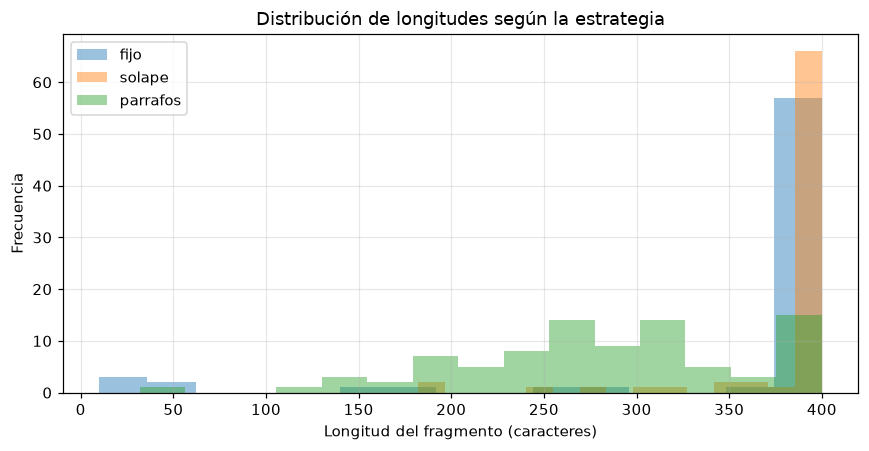

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for nombre, frags in fragmentos_por.items():
    ax.hist([len(f.texto) for f in frags], bins=15, alpha=0.45, label=nombre)
ax.set_xlabel("Longitud del fragmento (caracteres)")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribución de longitudes según la estrategia")
ax.legend()
fig.tight_layout()
fig.savefig(RUTAS["resultados"] / "fig_chunking_longitudes.png", dpi=130)
plt.show()


## 5. Embeber e indexar (NumPy, luego FAISS)

Usamos la estrategia **solape** por defecto. El índice NumPy es un producto
interno entre la consulta (normalizada) y la matriz de fragmentos: es la
similitud coseno, sin magia. FAISS hace lo mismo aquí (`IndexFlatIP`, búsqueda
exacta). En un corpus de decenas de fragmentos no hay ganancia de tiempo; FAISS
empieza a importar cuando hay cientos de miles o millones de vectores, o cuando
pasas a índices aproximados (IVF, HNSW). En este laboratorio nos basta ver que
**los resultados coinciden**.


In [9]:
fragmentos = fragmentos_por[ESTRATEGIA_DEFECTO]
print(f"Indexando {len(fragmentos)} fragmentos ({ESTRATEGIA_DEFECTO})")

codificador = Codificador(MODELO_EMB, dispositivo_destino=str(DEVICE))
t0 = time.perf_counter()
vectores = codificador.codificar([f.texto for f in fragmentos], lote=16, progreso=True)
t_emb = time.perf_counter() - t0
print(f"Embeddings: {vectores.shape} en {t_emb:.2f} s")

indice_np = IndiceNumpy(vectores, fragmentos)
indice_faiss = IndiceFAISS(vectores, fragmentos)
print("Indices listos (NumPy y FAISS).")


Indexando 77 fragmentos (solape)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

/workspace/rag/src/rag_utils.py:594: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  self.dim = int(self.modelo.get_sentence_embedding_dimension())


Batches:   0%|          | 0/5 [00:00<?, ?it/s]

Embeddings: (77, 384) en 9.13 s
Indices listos (NumPy y FAISS).


In [10]:
consulta = "¿Cuántos días de vacaciones tiene un empleado de NubeAndina?"
qv = codificador.codificar([consulta], progreso=False)[0]

top_np = indice_np.buscar(qv, k=4)
top_fa = indice_faiss.buscar(qv, k=4)

def tabla_hits(resultados):
    return pd.DataFrame([
        {
            "rango": r.rango,
            "puntuacion": round(r.puntuacion, 4),
            "id": r.fragmento.id,
            "doc": r.fragmento.doc_id,
            "extracto": r.fragmento.texto[:140].replace("\n", " ") + "...",
        }
        for r in resultados
    ])

print("Consulta:", consulta)
print("\nNumPy:")
display_np = tabla_hits(top_np)
print(display_np.to_string(index=False))
print("\nFAISS:")
display_fa = tabla_hits(top_fa)
print(display_fa.to_string(index=False))

ids_np = [r.fragmento.id for r in top_np]
ids_fa = [r.fragmento.id for r in top_fa]
print("\n¿Mismos identificadores, en el mismo orden?", ids_np == ids_fa)


Consulta: ¿Cuántos días de vacaciones tiene un empleado de NubeAndina?

NumPy:
 rango  puntuacion                                  id                             doc                                                                                                                                        extracto
     1      0.7291 nubeandina-vacaciones-y-trabajo::#0 nubeandina-vacaciones-y-trabajo # NubeAndina: vacaciones, presencialidad y trabajo remoto  Política interna de la empresa ficticia NubeAndina S.A.C. Solo aplica a este caso...
     2      0.6730 nubeandina-vacaciones-y-trabajo::#7 nubeandina-vacaciones-y-trabajo o con jornada reducida. Si un asistente afirma que NubeAndina ofrece 30 días de vacaciones, trabajo remoto ilimitado o «viernes libre», está...
     3      0.6663 nubeandina-vacaciones-y-trabajo::#6 nubeandina-vacaciones-y-trabajo liente por más de dos noches recibe un día hábil de descanso al regreso, que no descuenta vacaciones. El viaje se registra en *Huella* como .

Los dos índices deberían devolver los mismos fragmentos en el mismo orden (búsqueda
exacta, mismos vectores). Guardamos FAISS y la copia NumPy en `modelos/` para
no volver a embeber el corpus en los cuadernos siguientes, salvo que cambies
el troceado.


In [11]:
ruta_faiss = indice_faiss.guardar(RUTAS["modelos"] / "indice_faiss")
ruta_np = indice_np.guardar(RUTAS["modelos"] / "indice_numpy")
guardar_json(
    {
        "estrategia": ESTRATEGIA_DEFECTO,
        "tamano": TAMANO_CHUNK,
        "solape": SOLAPE,
        "modelo_embeddings": MODELO_EMB,
        "n_documentos": len(documentos),
        "n_fragmentos": len(fragmentos),
        "dim": int(vectores.shape[1]),
        "segundos_embeber": round(t_emb, 3),
        "resumenes_estrategias": resumenes,
        "consulta_demo": consulta,
        "ids_numpy": ids_np,
        "ids_faiss": ids_fa,
        "coinciden": ids_np == ids_fa,
    },
    RUTAS["resultados"] / "indexado.json",
)
print("Indices guardados en:")
print(" ", ruta_faiss)
print(" ", ruta_np)
print("Listo. Siguiente cuaderno: 03-recuperacion-y-busqueda.")


Indices guardados en:
  /workspace/rag/modelos/indice_faiss
  /workspace/rag/modelos/indice_numpy
Listo. Siguiente cuaderno: 03-recuperacion-y-busqueda.


## Recapitulando

- El *chunking* no es un detalle: corta o preserva hechos.
- El solape es un seguro barato contra los cortes.
- Un índice denso, en su forma más simple, es «matriz de vectores + coseno».
- FAISS, en modo exacto, replica eso y escala mejor cuando el corpus crece.

Siguiente: [03-recuperacion-y-busqueda.ipynb](03-recuperacion-y-busqueda.ipynb).
